# DASCM 2026 — Project Part 2: Data Preprocessing
## Dataset 3 — E-Commerce Sales & Customer Insights (regression target: `Shipping Fee`)

**Course:** MSCM-CO-07 Data Analytics in Supply Chain Management (Fall 2026)
**Group:** 1
**Notebook continues from:** `DASCM_2026_Part1_ECommerce_Sales_Customer_Insights_EDA.ipynb`
**Dataset:** `../data/realistic_e_commerce_sales_data.csv` (1,000 orders × 12 columns; this notebook is in the `Part2/` folder)

### Contribution of group members

| Group member | Contribution to this notebook (Dataset 3) |
|---|---|
| Mariem Nour Ghozzi (Athene) | Train/test split, missing-data analysis and imputation, outlier detection and handling, categorical encoding, feature scaling, feature engineering/selection, Markdown explanations |
| *[Team member 2 — name]* | *[e.g. review of preprocessing decisions / Dataset 1]* |
| *[Team member 3 — name]* | *[e.g. review of preprocessing decisions / Dataset 2]* |

### Preprocessing workflow in this notebook

| Step | Section | Method chosen |
|---|---|---|
| Split into training and test sets | 2 | 80 % / 20 % hold-out, stratified by `Product Name`, `random_state=42` |
| Missing values | 3 | Simple imputation (median for `Age`, most frequent for `Region`), fitted on training data only |
| Outliers | 4 | IQR detection (per product) → Winsorization (capping) at the training-set fences |
| Categorical encoding | 5 | Label encoding (`Gender`) and one-hot encoding (`Region`, `Product Name`, `Category`), applied in a `for` loop |
| Feature scaling | 6 | Standard scaling (z-score) of the numerical predictors |
| Other preprocessing | 7 | Feature engineering (cyclical date features) and feature selection (removal of redundant/leaking columns) |

**Golden rule used throughout:** every step that *learns something from the data* (medians, modes, IQR fences, encoder categories, scaler mean/standard deviation) is fitted on the **training set only** and then applied unchanged to the test set.

## 0. Setup and data loading

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# This notebook lives in the Part2/ folder; the dataset is in the repository's data/ folder
DATA_PATH = Path("../data/realistic_e_commerce_sales_data.csv")
if not DATA_PATH.exists():                     # fallback if the notebook is run from the repo root
    DATA_PATH = Path("data/realistic_e_commerce_sales_data.csv")
PLOT_DIR = Path("plots-4-part2")
PLOT_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("processed_data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Shipping Fee"
RANDOM_STATE = 42

def show_save(name):
    plt.savefig(PLOT_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (1000, 12)


,Customer ID,Gender,Region,Age,Product Name,Category,Unit Price,Quantity,Total Price,Shipping Fee,Shipping Status,Order Date
0,CUST0268,Male,North,NaN,Monitor,Electronics,300.0,5,1500,13.31,Returned,2023-12-08
1,CUST0046,Male,West,22.0,Headphones,Accessories,100.0,2,200,6.93,In Transit,2023-04-09
2,CUST0169,Female,South,54.0,Monitor,Electronics,300.0,1,300,11.31,Returned,2023-08-28
3,CUST0002,Male,North,23.0,Headphones,Accessories,100.0,5,500,12.22,Delivered,2023-01-18
4,CUST0173,Female,South,NaN,Laptop,Electronics,1500.0,3,4500,5.40,Delivered,2023-01-19


## 1. Starting point: what the Part 1 EDA told us

The EDA of Part 1 produced the following decisions that we carry into preprocessing:

* **Target:** `Shipping Fee` (continuous) → this is a **regression** task.
* **Excluded from the predictor set:**
  * `Customer ID` – an identifier with 292 distinct values; it carries no generalisable information about shipping cost and would let a model memorise customers.
  * `Shipping Status` – *Delivered / In Transit / Returned* is only known **after** the order has been shipped, i.e. after the fee was set. Using it would be **data leakage** (information from the future).
* **Missing values** were found in `Region`, `Age` and `Shipping Status`.
* **`Total Price`** was expected to equal `Unit Price × Quantity`.

A closer row-level check (below) shows that the last point is **not true for every row** — this is important for the outlier section.

In [3]:
df = df_raw.copy()
df["Order Date"] = pd.to_datetime(df["Order Date"])

expected = df["Unit Price"] * df["Quantity"]
mismatch = ~np.isclose(df["Total Price"], expected)
print("Rows where Total Price != Unit Price × Quantity:", mismatch.sum())

list_price = df.groupby("Product Name")["Unit Price"].agg(lambda s: s.mode()[0])
check = df.loc[mismatch, ["Product Name", "Unit Price", "Quantity", "Total Price"]].copy()
check["List price of product (mode)"] = check["Product Name"].map(list_price)
check["Total Price / Quantity"] = check["Total Price"] / check["Quantity"]
check["Unit Price / list price"] = (check["Unit Price"] / check["List price of product (mode)"]).round(4)
check.head(10)

Rows where Total Price != Unit Price × Quantity: 20


,Product Name,Unit Price,Quantity,Total Price,List price of product (mode),Total Price / Quantity,Unit Price / list price
26,Smartphone,1658.432327,2,1600,800.0,800.0,2.073
83,Mouse,62.191212,2,60,30.0,30.0,2.073
84,Keyboard,103.652020,4,200,50.0,50.0,2.073
110,Mouse,62.191212,2,60,30.0,30.0,2.073
194,Monitor,621.912122,5,1500,300.0,300.0,2.073
209,Monitor,621.912122,5,1500,300.0,300.0,2.073
215,Mouse,62.191212,1,30,30.0,30.0,2.073
226,Keyboard,103.652020,4,200,50.0,50.0,2.073
244,Monitor,621.912122,3,900,300.0,300.0,2.073
339,Headphones,207.304041,1,100,100.0,100.0,2.073


**Observation.** In 20 orders the recorded `Unit Price` is about **2.07 ×** the product's normal list price, while `Total Price / Quantity` still equals the normal list price. The order value is therefore internally consistent and only the unit price field is inflated — a strong sign of a **recording error** rather than a genuine premium sale. We keep this in mind for Section 4.

## 2. Splitting the dataset into training and test sets

Before splitting we only perform **row-wise, deterministic** operations that do not learn anything from the data distribution:

* parsing `Order Date` as a date (done above);
* removing the two columns excluded in Part 1 for conceptual reasons (`Customer ID` = identifier, `Shipping Status` = post-shipping leakage). Their missingness is still inspected in Section 3 on the raw data.

In [4]:
X = df.drop(columns=[TARGET, "Customer ID", "Shipping Status"])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=X["Product Name"],     # keep the same product mix in both sets
)

print(f"Training set: {X_train.shape}  ({len(X_train)/len(X):.0%})")
print(f"Test set:     {X_test.shape}  ({len(X_test)/len(X):.0%})")

compare = pd.DataFrame({
    "Train share": X_train["Product Name"].value_counts(normalize=True),
    "Test share": X_test["Product Name"].value_counts(normalize=True),
}).round(3)
display(compare)
print("Shipping Fee — train mean %.2f / test mean %.2f" % (y_train.mean(), y_test.mean()))

Training set: (800, 9)  (80%)
Test set:     (200, 9)  (20%)


,Train share,Test share
Product Name,,
Headphones,0.120,0.120
Keyboard,0.145,0.145
Laptop,0.154,0.155
Monitor,0.181,0.180
Mouse,0.136,0.135
Smartphone,0.141,0.145
Smartwatch,0.122,0.120


Shipping Fee — train mean 12.47 / test mean 12.21


### Why 20 % for the test set?

* The dataset is **small (1,000 rows)**. An 80/20 split keeps **800 rows for learning**, which is enough for the 20 predictors produced after encoding and feature engineering, while the **200 test rows** still give a reasonably stable estimate of the error (a 10 % test set would contain only 100 orders, and some products would then appear only ~12 times).
* 80/20 is the common default for data sets of this size; 70/30 would take too much data away from training for a weak-signal target like `Shipping Fee` (the EDA showed near-zero linear correlations).
* The split is **stratified by `Product Name`** so that every product (and therefore every category and price level) is represented in both sets in the same proportion — the table above confirms almost identical shares. A fixed `random_state` makes the split reproducible.
* A purely time-based split was not used because the orders cover only one calendar year and the EDA showed no trend over time; there is no forecasting element in the task.

### When is the split done, and why?

The split is done **immediately after loading and the row-wise cleaning, and before every other preprocessing step** (imputation, outlier handling, encoding, scaling, feature selection).

**Reason – avoiding data leakage:** every one of those later steps *estimates parameters from the data* (the median age, the most frequent region, the IQR fences, the list of categories, the mean and standard deviation for scaling). If those parameters were computed on the full dataset, information from the test rows would leak into the training process, and the test error would be over-optimistic. Therefore all parameters are learned with `.fit()` on `X_train` only, and the test set is transformed with exactly the same parameters, just as genuinely new orders would be in production.

## 3. Handling missing values

### 3.1 Identifying missing data with pandas

In [5]:
missing_tbl = pd.DataFrame({
    "Missing (full raw data)": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(1),
    "Missing in X_train": X_train.isna().sum().reindex(df_raw.columns),
    "Missing in X_test": X_test.isna().sum().reindex(df_raw.columns),
})
display(missing_tbl)
print("Rows with at least one missing value (raw):", df_raw.isna().any(axis=1).sum())
print("Rows with a missing value in the predictor columns (Age/Region):",
      df_raw[["Age", "Region"]].isna().any(axis=1).sum())

,Missing (full raw data),Missing %,Missing in X_train,Missing in X_test
Customer ID,0,0.0,NaN,NaN
Gender,0,0.0,0.0,0.0
Region,50,5.0,41.0,9.0
Age,100,10.0,76.0,24.0
Product Name,0,0.0,0.0,0.0
Category,0,0.0,0.0,0.0
Unit Price,0,0.0,0.0,0.0
Quantity,0,0.0,0.0,0.0
Total Price,0,0.0,0.0,0.0
Shipping Fee,0,0.0,NaN,NaN


Rows with at least one missing value (raw): 190
Rows with a missing value in the predictor columns (Age/Region): 146


Three columns contain missing values: `Age` (100 rows, 10 %), `Region` (50 rows, 5 %) and `Shipping Status` (50 rows, 5 %). All other columns, including the target, are complete. `Shipping Status` is not used as a predictor (leakage), so only **`Age` and `Region`** need to be handled. In the train/test columns, *NaN* simply means that the column was removed before the split.

### 3.2 Plotting missing data with missingno

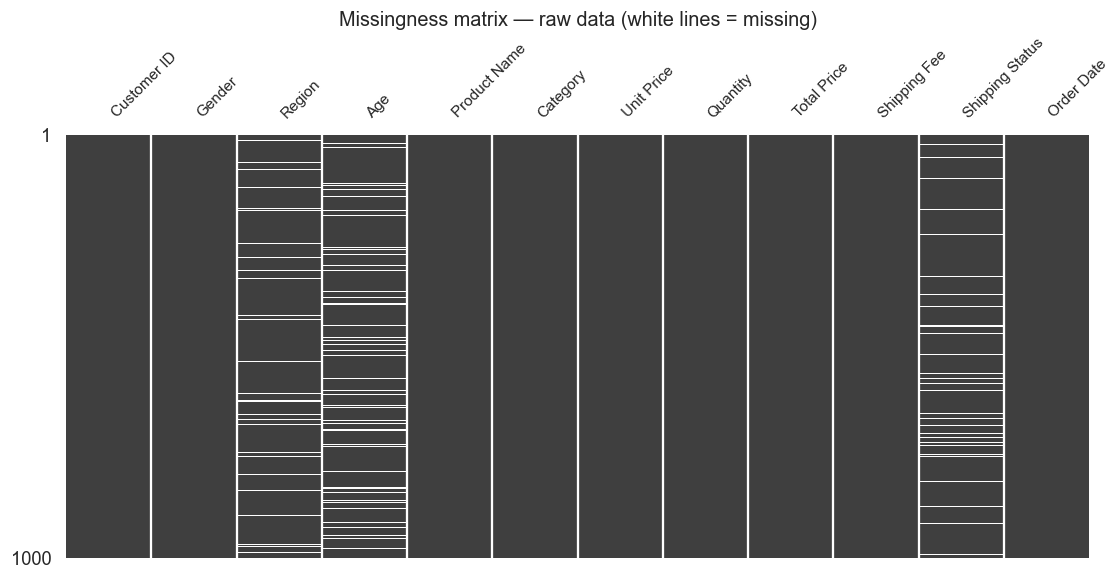

In [6]:
msno.matrix(df_raw, figsize=(12, 5), fontsize=10, sparkline=False)
plt.title("Missingness matrix — raw data (white lines = missing)", fontsize=13)
show_save("01_missingno_matrix")

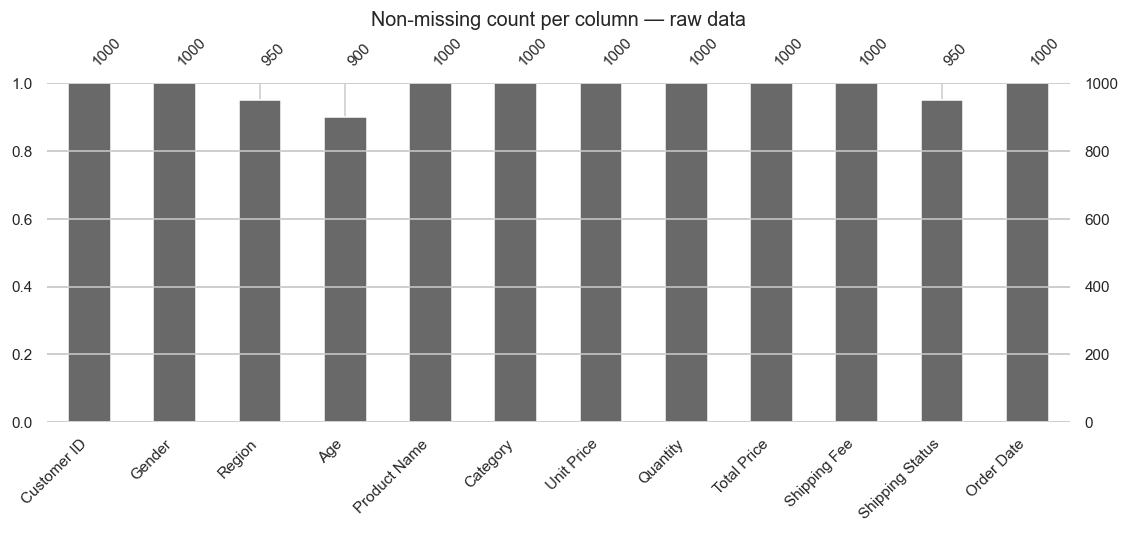

In [7]:
msno.bar(df_raw, figsize=(12, 4), fontsize=10)
plt.title("Non-missing count per column — raw data", fontsize=13)
show_save("02_missingno_bar")

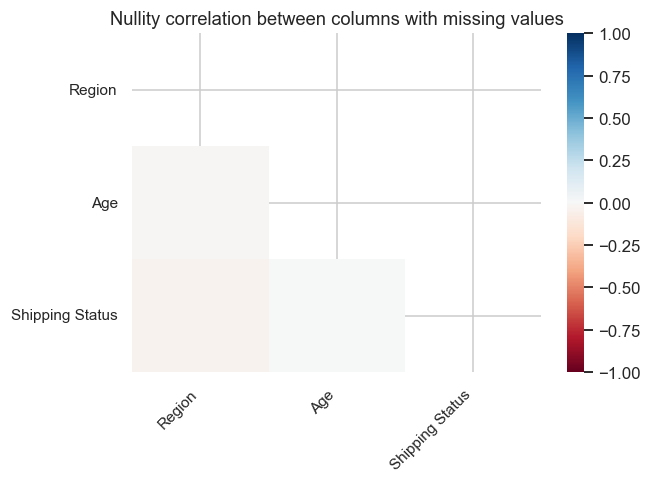

In [8]:
msno.heatmap(df_raw, figsize=(6, 4), fontsize=10)   # cells close to white = correlation ≈ 0
plt.title("Nullity correlation between columns with missing values", fontsize=12)
show_save("03_missingno_heatmap")

### 3.3 Which type of missing data is it (MCAR, MAR or MNAR)?

* **MCAR** – missingness is unrelated to any value in the data.
* **MAR** – missingness depends on *other observed* variables (e.g. age missing more often for one region).
* **MNAR** – missingness depends on the *unobserved value itself* (e.g. older customers refusing to state their age).

We test this with the data: for each column with missing values we create an indicator *(missing = 1)* and check whether the rows with a missing value differ from the complete rows in the other variables — Mann–Whitney U test for numerical variables, χ² test for categorical variables. If no difference is significant, MAR is not supported by the data.

In [9]:
def missingness_tests(data, col):
    flag = data[col].isna()
    rows = []
    for other in ["Age", "Unit Price", "Quantity", "Total Price", "Shipping Fee"]:
        if other == col:
            continue
        a, b = data.loc[flag, other].dropna(), data.loc[~flag, other].dropna()
        p = stats.mannwhitneyu(a, b).pvalue
        rows.append([col, other, "Mann-Whitney U", round(a.mean(), 2), round(b.mean(), 2), round(p, 3)])
    for other in ["Gender", "Region", "Product Name", "Category", "Shipping Status"]:
        if other == col:
            continue
        sub = data[[other]].assign(flag=flag).dropna()
        p = stats.chi2_contingency(pd.crosstab(sub[other], sub["flag"]))[1]
        rows.append([col, other, "Chi-square", "-", "-", round(p, 3)])
    return pd.DataFrame(rows, columns=["Missing column", "Compared with", "Test",
                                       "Mean if missing", "Mean if present", "p-value"])

mcar_tbl = pd.concat([missingness_tests(df_raw, "Age"), missingness_tests(df_raw, "Region")],
                     ignore_index=True)
mcar_tbl["Significant (p<0.05)"] = mcar_tbl["p-value"] < 0.05
alpha_bonf = 0.05 / len(mcar_tbl)          # Bonferroni correction for multiple tests
mcar_tbl["Significant after Bonferroni"] = mcar_tbl["p-value"] < alpha_bonf
print(f"{len(mcar_tbl)} tests -> Bonferroni-corrected significance level = {alpha_bonf:.4f}")
display(mcar_tbl)

# Co-occurrence of missing values vs. what independence would predict
obs = (df_raw["Age"].isna() & df_raw["Region"].isna()).sum()
exp = df_raw["Age"].isna().mean() * df_raw["Region"].isna().mean() * len(df_raw)
print(f"Age and Region missing together: observed {obs}, expected under independence {exp:.1f}")

18 tests -> Bonferroni-corrected significance level = 0.0028


,Missing column,Compared with,Test,Mean if missing,Mean if present,p-value,Significant (p<0.05),Significant after Bonferroni
0,Age,Unit Price,Mann-Whitney U,488.74,454.26,0.983,False,False
1,Age,Quantity,Mann-Whitney U,3.23,2.98,0.100,False,False
2,Age,Total Price,Mann-Whitney U,1654.4,1312.4,0.552,False,False
3,Age,Shipping Fee,Mann-Whitney U,11.93,12.47,0.274,False,False
4,Age,Gender,Chi-square,-,-,0.688,False,False
5,Age,Region,Chi-square,-,-,0.531,False,False
6,Age,Product Name,Chi-square,-,-,0.705,False,False
7,Age,Category,Chi-square,-,-,0.710,False,False
8,Age,Shipping Status,Chi-square,-,-,0.606,False,False
9,Region,Age,Mann-Whitney U,42.93,46.9,0.047,True,False


Age and Region missing together: observed 4, expected under independence 5.0


**Interpretation — the missing data are best described as MCAR (Missing Completely At Random).**

* **Almost no test is significant:** rows with a missing `Age` or `Region` have practically the same shipping fee, unit price, quantity, gender, product and category mix as the complete rows. The only exception is a borderline result for *Region missing vs. Age* (p ≈ 0.047; customers without a region are on average ~4 years younger). However, we ran 18 tests: at a 5 % level about one "significant" result is expected purely by chance, and after the **Bonferroni correction** (level 0.05/18 ≈ 0.0028) **no test remains significant**. There is therefore no reliable evidence that the missingness depends on observed variables, which argues against **MAR**.
* **The missingno heatmap shows nullity correlations of almost zero** (all cells are nearly white; missingno hides values whose magnitude is below 0.05), and `Age` and `Region` are missing together about as often as pure chance predicts (observed vs. expected count above). The matrix plot also shows the gaps scattered evenly over the file, without blocks or a time pattern.
* The missing rates are "round" (exactly 10 % and 5 %), which is typical of values removed at random, e.g. optional fields in a web checkout form that some customers simply skip.
* **MNAR cannot be fully excluded** — by definition we never see the missing ages, so we cannot prove that, e.g., older customers did not hide their age. However, nothing in the observed data points that way (the age distribution of the observed values is smooth from 18 to 69, without a truncated tail), so MCAR is the most plausible assumption.

Under MCAR, the complete rows are a representative sample, so a simple imputation does not introduce systematic bias in the relationships between the variables.

### 3.4 Handling the missing data — simple imputation (median / most frequent)

In [10]:
X_train_before_imp = X_train.copy()   # kept for the before/after comparison

num_imputer = SimpleImputer(strategy="median")          # Age
cat_imputer = SimpleImputer(strategy="most_frequent")   # Region

num_imputer.fit(X_train[["Age"]])
cat_imputer.fit(X_train[["Region"]])
print("Learned from training data only -> median Age:", num_imputer.statistics_[0],
      "| most frequent Region:", cat_imputer.statistics_[0])

for part in (X_train, X_test):
    part["Age"] = num_imputer.transform(part[["Age"]]).ravel()
    part["Region"] = cat_imputer.transform(part[["Region"]]).ravel()

print("Missing values left in X_train:", int(X_train.isna().sum().sum()),
      "| in X_test:", int(X_test.isna().sum().sum()))

Learned from training data only -> median Age: 50.0 | most frequent Region: South
Missing values left in X_train: 0 | in X_test: 0


### 3.5 Why simple imputation?

* **Dropping rows was rejected:** 146 of 1,000 orders (≈ 15 %) have a missing `Age` or `Region`. With only 1,000 rows, deleting them would throw away a large part of the information in the *other* columns (product, price, quantity, target), even though the data are MCAR and those values are perfectly valid.
* **Median for `Age`:** `Age` is numerical and its distribution is roughly uniform/slightly left-skewed (18–69). The median is robust and always produces a realistic age. With MCAR data, the median of the observed ages is an unbiased "typical" value.
* **Most frequent value for `Region`:** `Region` is nominal (North/South/East/West), so a mean or median is impossible, and the mode always produces a valid category. Because all missing regions go to one category, that region's share rises by the missing rate (≈ 5 percentage points) — an accepted cost given that `Region` showed only a weak relationship with the target in the EDA (see the effects in 3.6).
* **Why not KNN or iterative imputation?** These methods are useful when the missing variable can be *predicted* from the other variables. Here the EDA showed that `Age` and `Region` are practically unrelated to the other columns (correlations ≈ 0), so a KNN/iterative imputer would just return values close to the average while adding complexity and a risk of overfitting. ffill/bfill/interpolation assume an ordering of the rows (time series) that does not exist for independent customer orders.
* **Leakage-free:** both imputers are fitted on `X_train` only and re-used on `X_test`.

### 3.6 Visualisation before vs. after imputation — what is the effect?

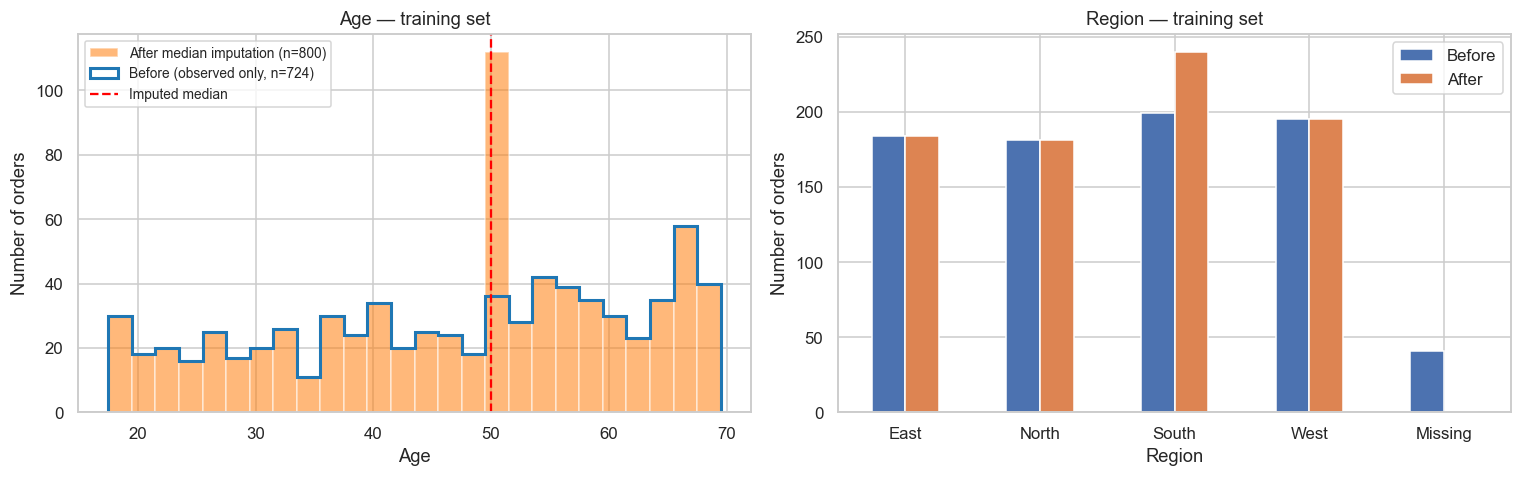

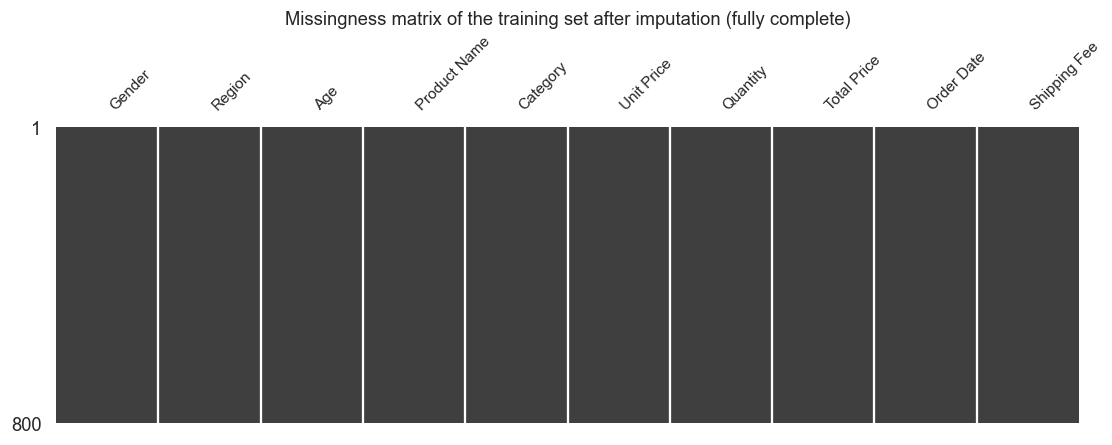

,Age before (observed),Age after imputation
count,724.00,800.00
mean,47.00,47.29
std,15.18,14.46
min,18.00,18.00
25%,35.00,37.00
50%,50.00,50.00
75%,60.00,58.00
max,69.00,69.00


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

before_age = X_train_before_imp["Age"].dropna()
after_age = X_train["Age"]
bins = np.arange(17.5, 70.5, 2)
axes[0].hist(after_age, bins=bins, color="tab:orange", alpha=0.55, label=f"After median imputation (n={len(after_age)})")
axes[0].hist(before_age, bins=bins, histtype="step", linewidth=2, color="tab:blue", label=f"Before (observed only, n={len(before_age)})")
axes[0].axvline(num_imputer.statistics_[0], color="red", ls="--", label="Imputed median")
axes[0].set(title="Age — training set", xlabel="Age", ylabel="Number of orders")
axes[0].legend(fontsize=9)

reg = pd.DataFrame({
    "Before": X_train_before_imp["Region"].fillna("Missing").value_counts(),
    "After": X_train["Region"].value_counts(),
}).fillna(0).loc[["East", "North", "South", "West", "Missing"]]
reg.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set(title="Region — training set", xlabel="Region", ylabel="Number of orders")
plt.tight_layout()
show_save("04_missing_before_after")

msno.matrix(pd.concat([X_train, y_train], axis=1), figsize=(12, 3.5), fontsize=10, sparkline=False)
plt.title("Missingness matrix of the training set after imputation (fully complete)", fontsize=12)
show_save("05_missingno_after")

stats_tbl = pd.DataFrame({
    "Age before (observed)": before_age.describe(),
    "Age after imputation": after_age.describe(),
}).round(2)
display(stats_tbl)

**Effects of handling the missing data**

* **No information is lost:** the training set keeps all 800 orders (instead of 685 after listwise deletion — 115 training rows have a missing `Age` or `Region`), and the missingno matrix is now completely filled, so all later steps and models can use every row.
* **Centre of the `Age` distribution is preserved:** the median stays at 50 and the mean moves by only ≈ 0.3 years (47.0 → 47.3).
* **Side effect 1 – reduced variance of `Age`:** all 76 imputed ages receive the same value, so a spike appears at 50 (orange bar) and the standard deviation decreases from ≈ 15.2 to ≈ 14.5. The interquartile range also narrows (35–60 → 37–58).
* **Side effect 2 – one region becomes over-represented:** the 41 missing regions are all assigned to *South* (the training mode), so South rises from ≈ 25 % to 30 % of the training orders while the other regions are unchanged.
* **Assessment:** these distortions are the known limitation of simple imputation. They are acceptable here because only 10 % / 5 % of the values were missing, the data are MCAR, and `Age` and `Region` were only weakly related to `Shipping Fee` in the EDA. With a higher missing rate, or a stronger link to the target, a model-based method (KNN / iterative imputation) or an explicit "Unknown" category would be preferable.

## 4. Detecting and handling outliers

### 4.1 Detection with the IQR method

A value is flagged if it lies outside **[Q1 − 1.5·IQR, Q3 + 1.5·IQR]**. We apply it in two ways and compare:

1. **Global IQR** on each numerical column (as in the Part 1 EDA).
2. **IQR per product** for `Unit Price`. The unit price is a property of the product (a mouse is always cheap, a laptop always expensive), so a "normal" price must be judged *within* each product, not across products. All fences are computed on the **training set**.

In [12]:
num_cols = ["Age", "Unit Price", "Quantity", "Total Price"]

def iqr_fences(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

rows = []
for col in num_cols:
    lo, hi = iqr_fences(X_train[col])
    n = ((X_train[col] < lo) | (X_train[col] > hi)).sum()
    rows.append([col, lo, hi, n])
lo, hi = iqr_fences(y_train)
rows.append([TARGET + " (target)", lo, hi, ((y_train < lo) | (y_train > hi)).sum()])
global_tbl = pd.DataFrame(rows, columns=["Column", "Lower fence", "Upper fence", "Outliers in train"])
print("Global IQR (training set):")
display(global_tbl.round(2))

# IQR per product for Unit Price — fences learned on the training set
price_fences = X_train.groupby("Product Name")["Unit Price"].apply(iqr_fences).apply(pd.Series)
price_fences.columns = ["Lower fence", "Upper fence"]

def flag_price_outliers(data):
    lo = data["Product Name"].map(price_fences["Lower fence"])
    hi = data["Product Name"].map(price_fences["Upper fence"])
    return (data["Unit Price"] < lo) | (data["Unit Price"] > hi)

out_train = flag_price_outliers(X_train)
out_test = flag_price_outliers(X_test)
price_fences["Outliers in train"] = X_train[out_train]["Product Name"].value_counts()
price_fences["Outliers in test"] = X_test[out_test]["Product Name"].value_counts()
print("IQR per product for Unit Price:")
display(price_fences.fillna(0).round(2))
print(f"Unit Price outliers — train: {out_train.sum()}, test: {out_test.sum()}")

Global IQR (training set):


,Column,Lower fence,Upper fence,Outliers in train
0,Age,5.50,89.50,0
1,Unit Price,-1075.00,1925.00,1
2,Quantity,-1.00,7.00,0
3,Total Price,-1750.00,3450.00,98
4,Shipping Fee (target),-2.66,27.42,0


IQR per product for Unit Price:


,Lower fence,Upper fence,Outliers in train,Outliers in test
Product Name,,,,
Headphones,100.0,100.0,2.0,0.0
Keyboard,50.0,50.0,2.0,0.0
Laptop,1500.0,1500.0,1.0,3.0
Monitor,300.0,300.0,3.0,2.0
Mouse,30.0,30.0,4.0,0.0
Smartphone,800.0,800.0,0.0,3.0
Smartwatch,200.0,200.0,0.0,0.0


Unit Price outliers — train: 12, test: 8


**Result of the detection**

* `Age`, `Quantity` and the target `Shipping Fee` contain **no outliers**: they lie in bounded ranges (18–69 years, 1–5 units, 5–20 currency units).
* `Total Price` has 98 training values (≈ 12 %) above the global upper fence of 3,450. These are large but **genuine** orders (an expensive product × a high quantity; `Total Price` is consistent with the list price), so they are not errors.
* The **global** IQR on `Unit Price` catches only **1** of the 12 wrong prices in the training set (an inflated laptop price), because mixing seven products with very different price levels makes the global IQR very wide.
* The **per-product IQR** finds *all* inflated prices: each product has one fixed list price, so its IQR is 0 and the fences collapse onto that price. Every deviating price (the ~2.07 × values identified in Section 1) is flagged — in both the training and the test set.

The plot below makes this visible.

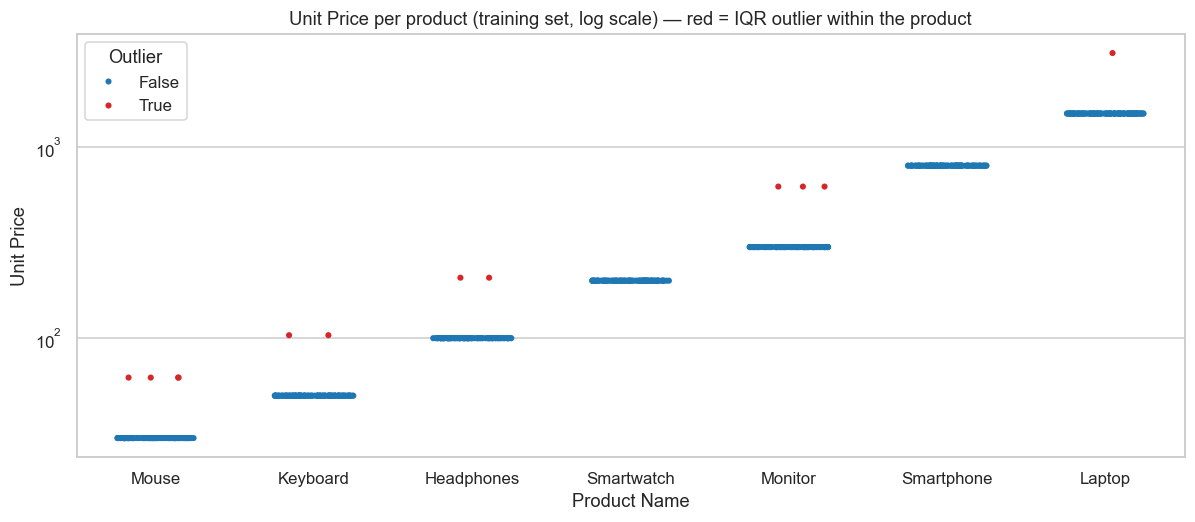

In [13]:
fig, ax = plt.subplots(figsize=(13, 5))
order = list_price.sort_values().index
sns.stripplot(data=X_train.assign(Outlier=out_train), x="Product Name", y="Unit Price",
              hue="Outlier", order=order, jitter=0.25, size=4, palette={False: "tab:blue", True: "tab:red"}, ax=ax)
ax.set_yscale("log")
ax.set_title("Unit Price per product (training set, log scale) — red = IQR outlier within the product")
show_save("06_unit_price_outliers_detection")

### 4.2 Handling the outliers — Winsorization (capping at the IQR fences)

In [14]:
X_train_before_out = X_train.copy()
X_test_before_out = X_test.copy()

def winsorize_unit_price(data):
    lo = data["Product Name"].map(price_fences["Lower fence"])
    hi = data["Product Name"].map(price_fences["Upper fence"])
    data["Unit Price"] = data["Unit Price"].clip(lower=lo, upper=hi)
    return data

X_train = winsorize_unit_price(X_train)
X_test = winsorize_unit_price(X_test)

for name, part in [("train", X_train), ("test", X_test)]:
    consistent = np.isclose(part["Total Price"], part["Unit Price"] * part["Quantity"]).all()
    print(f"{name}: remaining Unit Price outliers = {flag_price_outliers(part).sum()}, "
          f"Total Price == Unit Price × Quantity for every row: {consistent}")

train: remaining Unit Price outliers = 0, Total Price == Unit Price × Quantity for every row: True
test: remaining Unit Price outliers = 0, Total Price == Unit Price × Quantity for every row: True


### 4.3 Why IQR detection and Winsorization?

**Detection – IQR (applied per product):**
* The IQR rule is based on quartiles and does **not assume a normal distribution**. The Z-score was rejected because `Unit Price` is strongly skewed and multi-modal (seven price levels), so its mean and standard deviation are themselves distorted by the extreme values and |z| > 3 would miss most of them.
* Isolation Forest was rejected because it is a black-box method that needs a contamination parameter and is designed for multivariate anomalies in larger datasets; here the problem is one interpretable column with a clear business rule (one list price per product).
* Applying the IQR **within each product** turns the rule into a domain-aware check ("is this price normal *for this product*?"), which caught 100 % of the inconsistent prices while the global IQR caught only a fraction.

**Handling – Winsorization:**
* The outliers are **recording errors in a single field** — the rest of the row (product, quantity, total price, shipping fee, customer data) is valid, as the consistent `Total Price` proves. **Removal** would throw away 20 otherwise valid orders (and their target values), which is wasteful with only 1,000 rows, and would also not be possible for new orders in production.
* **Transformation** (e.g. log) would only compress the wrong values, they would still be wrong.
* **Winsorization caps each value at the fence learned from the training set.** Because each product's fences equal its list price, capping replaces the inflated price with the correct list price. This is confirmed by the check above: after capping, `Total Price = Unit Price × Quantity` holds for **every** row in both sets.
* `Total Price` outliers (large genuine orders) and the other columns are **left unchanged** — they are real observations, and removing them would hide exactly the large orders that may have different shipping fees.

### 4.4 Visualisation before vs. after handling outliers — what is the effect?

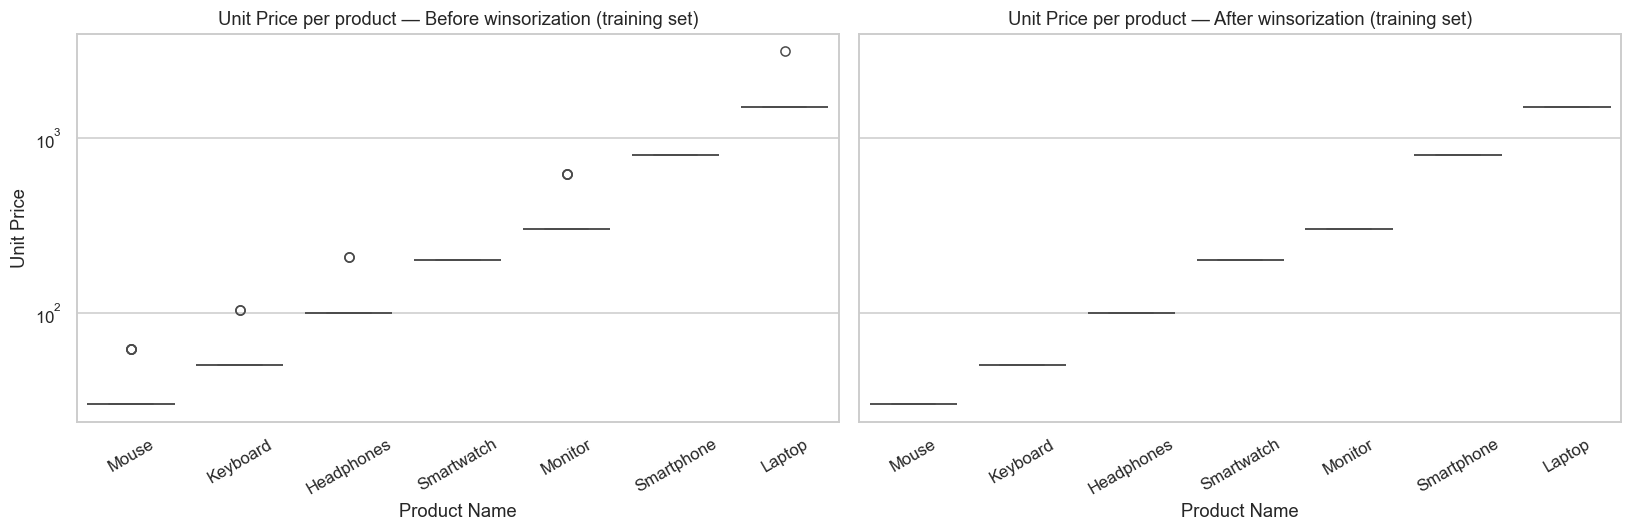

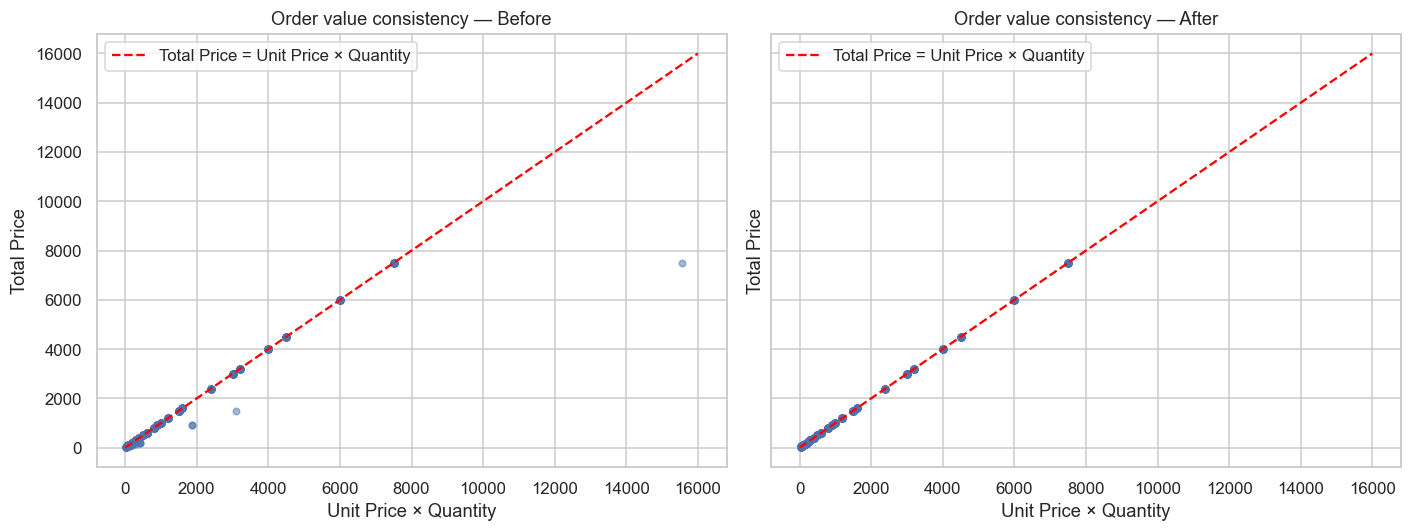

,Before,After
Mean,449.620,445.838
Std,517.607,510.676
Max,3109.561,1500.000
Skewness,1.300,1.208
Corr. with Total Price,0.850,0.849
Outliers (per-product IQR),12.000,0.000


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, data, title in [(axes[0], X_train_before_out, "Before winsorization"),
                        (axes[1], X_train, "After winsorization")]:
    sns.boxplot(data=data, x="Product Name", y="Unit Price", order=order, ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"Unit Price per product — {title} (training set)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
show_save("07_outliers_boxplot_before_after")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, data, title in [(axes[0], X_train_before_out, "Before"), (axes[1], X_train, "After")]:
    ax.scatter(data["Unit Price"] * data["Quantity"], data["Total Price"], alpha=0.5, s=18)
    lim = [0, 16000]
    ax.plot(lim, lim, color="red", ls="--", label="Total Price = Unit Price × Quantity")
    ax.set(title=f"Order value consistency — {title}", xlabel="Unit Price × Quantity", ylabel="Total Price")
    ax.legend()
plt.tight_layout()
show_save("08_outliers_consistency_before_after")

effect = pd.DataFrame({
    "Before": [X_train_before_out["Unit Price"].mean(), X_train_before_out["Unit Price"].std(),
               X_train_before_out["Unit Price"].max(), X_train_before_out["Unit Price"].skew(),
               X_train_before_out["Unit Price"].corr(X_train_before_out["Total Price"]),
               flag_price_outliers(X_train_before_out).sum()],
    "After": [X_train["Unit Price"].mean(), X_train["Unit Price"].std(), X_train["Unit Price"].max(),
              X_train["Unit Price"].skew(), X_train["Unit Price"].corr(X_train["Total Price"]),
              flag_price_outliers(X_train).sum()],
}, index=["Mean", "Std", "Max", "Skewness", "Corr. with Total Price", "Outliers (per-product IQR)"]).round(3)
display(effect)

**Effects of handling the outliers**

* **The box plots** show that every product now has exactly one price level — the isolated points above each box (the inflated prices) have disappeared, and no row was deleted (800 training orders before and after).
* **The consistency plot** shows that the points which were off the red line before (unit price × quantity much larger than the total price) now lie exactly on it: the dataset is internally consistent.
* **Statistics:** the maximum unit price drops from ≈ 3,110 to 1,500, the mean, standard deviation and skewness decrease slightly, and the number of per-product outliers falls from 12 to 0. The global statistics change only a little because just 1.5 % of the training rows were affected — the gain is in **correctness at row level**, not in the overall distribution.
* **Consequence for modelling:** a regression model will no longer learn from impossible prices (e.g. a laptop at 3,110), which would have pulled coefficients and created artificially extreme values for scaling in Section 6.

## 5. Encoding categorical data

### 5.1 Columns with categorical values

In [16]:
cat_cols = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

cat_info = pd.DataFrame({
    "Column": cat_cols,
    "Number of categories": [X_train[c].nunique() for c in cat_cols],
    "Categories": [sorted(X_train[c].unique()) for c in cat_cols],
    "Scale": ["Nominal (binary)" if X_train[c].nunique() == 2 else "Nominal" for c in cat_cols],
})
display(cat_info)

,Column,Number of categories,Categories,Scale
0,Gender,2,"[Female, Male]",Nominal (binary)
1,Region,4,"[East, North, South, West]",Nominal
2,Product Name,7,"[Headphones, Keyboard, Laptop, Monitor, Mouse,...",Nominal
3,Category,3,"[Accessories, Electronics, Wearables]",Nominal


All four remaining categorical predictors are **nominal**: there is no natural order between *Male/Female*, between the four regions, between the seven products, or between *Accessories / Electronics / Wearables*.

The dataset contains **no ordinal predictor**. The only column with a possible order is `Shipping Status` (*In Transit → Delivered → Returned* follows the fulfilment process), but it was excluded before the split because it is only known after the shipping fee was charged (leakage). `Quantity` (1–5) is ordered, but it is a true count and is therefore treated as a numerical variable.

### 5.2 Encoding each categorical column (loop)

In [17]:
encoding_plan = {
    "Gender": "label",          # binary nominal  -> one 0/1 column
    "Region": "onehot",         # 4 nominal categories
    "Product Name": "onehot",   # 7 nominal categories
    "Category": "onehot",       # 3 nominal categories
}

X_train_enc, X_test_enc = X_train.copy(), X_test.copy()
fitted_encoders = {}

for col, method in encoding_plan.items():
    if method == "label":
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        enc.fit(X_train[[col]])                                   # fit on training data only
        X_train_enc[col] = enc.transform(X_train[[col]]).ravel().astype(int)
        X_test_enc[col] = enc.transform(X_test[[col]]).ravel().astype(int)
        print(f"{col}: label encoding -> {dict(zip(enc.categories_[0], range(len(enc.categories_[0]))))}")
    elif method == "onehot":
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        enc.fit(X_train[[col]])                                   # fit on training data only
        new_cols = enc.get_feature_names_out([col])
        X_train_enc = pd.concat([X_train_enc.drop(columns=col),
                                 pd.DataFrame(enc.transform(X_train[[col]]), columns=new_cols,
                                              index=X_train.index).astype(int)], axis=1)
        X_test_enc = pd.concat([X_test_enc.drop(columns=col),
                                pd.DataFrame(enc.transform(X_test[[col]]), columns=new_cols,
                                             index=X_test.index).astype(int)], axis=1)
        print(f"{col}: one-hot encoding -> {len(new_cols)} columns {list(new_cols)}")
    fitted_encoders[col] = enc

print("\nShape after encoding — train:", X_train_enc.shape, "| test:", X_test_enc.shape)
X_train_enc.head()

Gender: label encoding -> {'Female': 0, 'Male': 1}
Region: one-hot encoding -> 4 columns ['Region_East', 'Region_North', 'Region_South', 'Region_West']
Product Name: one-hot encoding -> 7 columns ['Product Name_Headphones', 'Product Name_Keyboard', 'Product Name_Laptop', 'Product Name_Monitor', 'Product Name_Mouse', 'Product Name_Smartphone', 'Product Name_Smartwatch']
Category: one-hot encoding -> 3 columns ['Category_Accessories', 'Category_Electronics', 'Category_Wearables']

Shape after encoding — train: (800, 20) | test: (200, 20)


,Gender,Age,Unit Price,Quantity,Total Price,Order Date,Region_East,Region_North,Region_South,Region_West,Product Name_Headphones,Product Name_Keyboard,Product Name_Laptop,Product Name_Monitor,Product Name_Mouse,Product Name_Smartphone,Product Name_Smartwatch,Category_Accessories,Category_Electronics,Category_Wearables
776,0,67.0,30.0,4,120,2023-02-20,0,1,0,0,0,0,0,0,1,0,0,1,0,0
809,0,38.0,50.0,5,250,2023-05-12,0,0,1,0,0,1,0,0,0,0,0,1,0,0
876,1,57.0,1500.0,5,7500,2023-05-18,0,0,0,1,0,0,1,0,0,0,0,0,1,0
669,0,29.0,200.0,4,800,2023-02-25,1,0,0,0,0,0,0,0,0,0,1,0,0,1
363,0,25.0,50.0,4,200,2023-10-24,1,0,0,0,0,1,0,0,0,0,0,1,0,0


### 5.3 Why these encodings?

| Column | Type | Encoding | Reason |
|---|---|---|---|
| `Gender` | Nominal, 2 categories | **Label encoding** (Female = 0, Male = 1) | With only two categories, a single 0/1 column contains all the information. An order between 0 and 1 is meaningless for a binary variable, so label encoding does not introduce a false ranking; one-hot would just create two perfectly redundant columns. |
| `Region` | Nominal, 4 categories | **One-hot encoding** | Label encoding (e.g. East = 0 … West = 3) would tell a regression model that West is "three times" East and that North lies between East and South — a false order and distance. One-hot gives every region its own 0/1 column, so the model can learn a separate shipping-fee effect per region (the EDA hypothesised regional shipping zones). 4 categories → only 4 columns. |
| `Product Name` | Nominal, 7 categories | **One-hot encoding** | Same reasoning: products have no order. 7 columns are still manageable for 800 training rows (no high-cardinality problem). Each product represents different physical characteristics (size/weight) that may drive the fee. |
| `Category` | Nominal, 3 categories | **One-hot encoding** | No order between Accessories, Electronics and Wearables; 3 columns. (Its redundancy with `Product Name` is handled in Section 7.) |

*Nominal (target/frequency) encoding* was not chosen because it uses the target and can leak target information if not done with careful cross-validation, and because the low cardinality makes one-hot both safe and interpretable. *One-cold encoding* (inverse of one-hot) carries exactly the same information as one-hot but is less common and less readable, so it brings no advantage.

All encoders are fitted on the training set; `handle_unknown` ensures that a category that appears only in new data does not crash the pipeline.

## 6. Feature scaling

### 6.1 Columns with numerical values

In [18]:
num_cols = ["Age", "Unit Price", "Quantity", "Total Price"]
binary_cols = [c for c in X_train_enc.columns if set(X_train_enc[c].unique()) <= {0, 1}]
print("Continuous / discrete numerical predictors to scale:", num_cols)
print("Binary 0/1 columns from encoding (not scaled):", binary_cols)
display(X_train_enc[num_cols].describe().T.round(2))

Continuous / discrete numerical predictors to scale: ['Age', 'Unit Price', 'Quantity', 'Total Price']
Binary 0/1 columns from encoding (not scaled): ['Gender', 'Region_East', 'Region_North', 'Region_South', 'Region_West', 'Product Name_Headphones', 'Product Name_Keyboard', 'Product Name_Laptop', 'Product Name_Monitor', 'Product Name_Mouse', 'Product Name_Smartphone', 'Product Name_Smartwatch', 'Category_Accessories', 'Category_Electronics', 'Category_Wearables']


,count,mean,std,min,25%,50%,75%,max
Age,800.0,47.29,14.46,18.0,37.0,50.0,58.0,69.0
Unit Price,800.0,445.84,510.68,30.0,50.0,200.0,800.0,1500.0
Quantity,800.0,3.02,1.41,1.0,2.0,3.0,4.0,5.0
Total Price,800.0,1336.14,1801.61,30.0,200.0,600.0,1500.0,7500.0


The four numerical predictors live on very different scales: `Quantity` is 1–5, `Age` 18–69, `Unit Price` 30–1,500 and `Total Price` up to 7,500. Without scaling, any distance-based or regularised model would be dominated by the price columns simply because their numbers are bigger. The target `Shipping Fee` is **not** scaled, so that prediction errors stay in the original currency unit and remain easy to interpret.

### 6.2 Standard scaling (z-score)

In [19]:
scaler = StandardScaler()
scaler.fit(X_train_enc[num_cols])                 # mean and std learned on the training set only

X_train_scaled, X_test_scaled = X_train_enc.copy(), X_test_enc.copy()
X_train_scaled[num_cols] = scaler.transform(X_train_enc[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test_enc[num_cols])

print(pd.DataFrame({"Learned mean": scaler.mean_, "Learned std": scaler.scale_}, index=num_cols).round(2))
print("\nAfter scaling (training set):")
display(X_train_scaled[num_cols].describe().T[["mean", "std", "min", "max"]].round(3))
print("After scaling (test set, transformed with the training parameters):")
display(X_test_scaled[num_cols].describe().T[["mean", "std", "min", "max"]].round(3))

             Learned mean  Learned std
Age                 47.29        14.45
Unit Price         445.84       510.36
Quantity             3.02         1.41
Total Price       1336.14      1800.48

After scaling (training set):


,mean,std,min,max
Age,-0.0,1.001,-2.026,1.502
Unit Price,-0.0,1.001,-0.815,2.066
Quantity,0.0,1.001,-1.433,1.410
Total Price,-0.0,1.001,-0.725,3.423


After scaling (test set, transformed with the training parameters):


,mean,std,min,max
Age,-0.091,0.932,-2.026,1.502
Unit Price,0.008,1.005,-0.815,2.066
Quantity,-0.029,0.991,-1.433,1.410
Total Price,0.029,1.090,-0.725,3.423


### 6.3 Why standard scaling?

* **Outliers were already handled in Section 4**, so the main weakness of standard scaling — mean and standard deviation being pulled by extreme values — no longer applies. The advantage of **robust scaling** (median/IQR) is therefore not needed. It would even be problematic here: `Quantity` takes only 5 values and `Unit Price` only 7, so their IQR-based scales would depend on just a couple of discrete levels.
* **Min-max scaling** squeezes everything into [0, 1] using only the two most extreme values. For `Total Price` (most orders below 1,500 but a maximum of 7,500) almost all observations would be compressed into the lower 20 % of the range. The same applies to **max-abs scaling**, which is meant mainly for sparse data centred at 0.
* **Standard scaling** gives every numerical feature a mean of 0 and a standard deviation of 1. That puts the features on a comparable footing for the models we expect to use in the next part (linear/ridge/lasso regression with regularisation penalties, KNN, SVR, gradient-based methods), and the scaled values can be read directly as "how many standard deviations from the average order".
* Only the scale changes, not the shape of the distributions, so the relationships found in the EDA are preserved. Tree-based models are not affected by scaling at all, so the choice does not harm them.
* The 0/1 dummy columns are left unscaled because they are already on a common, interpretable scale.

### 6.4 Distribution before vs. after scaling

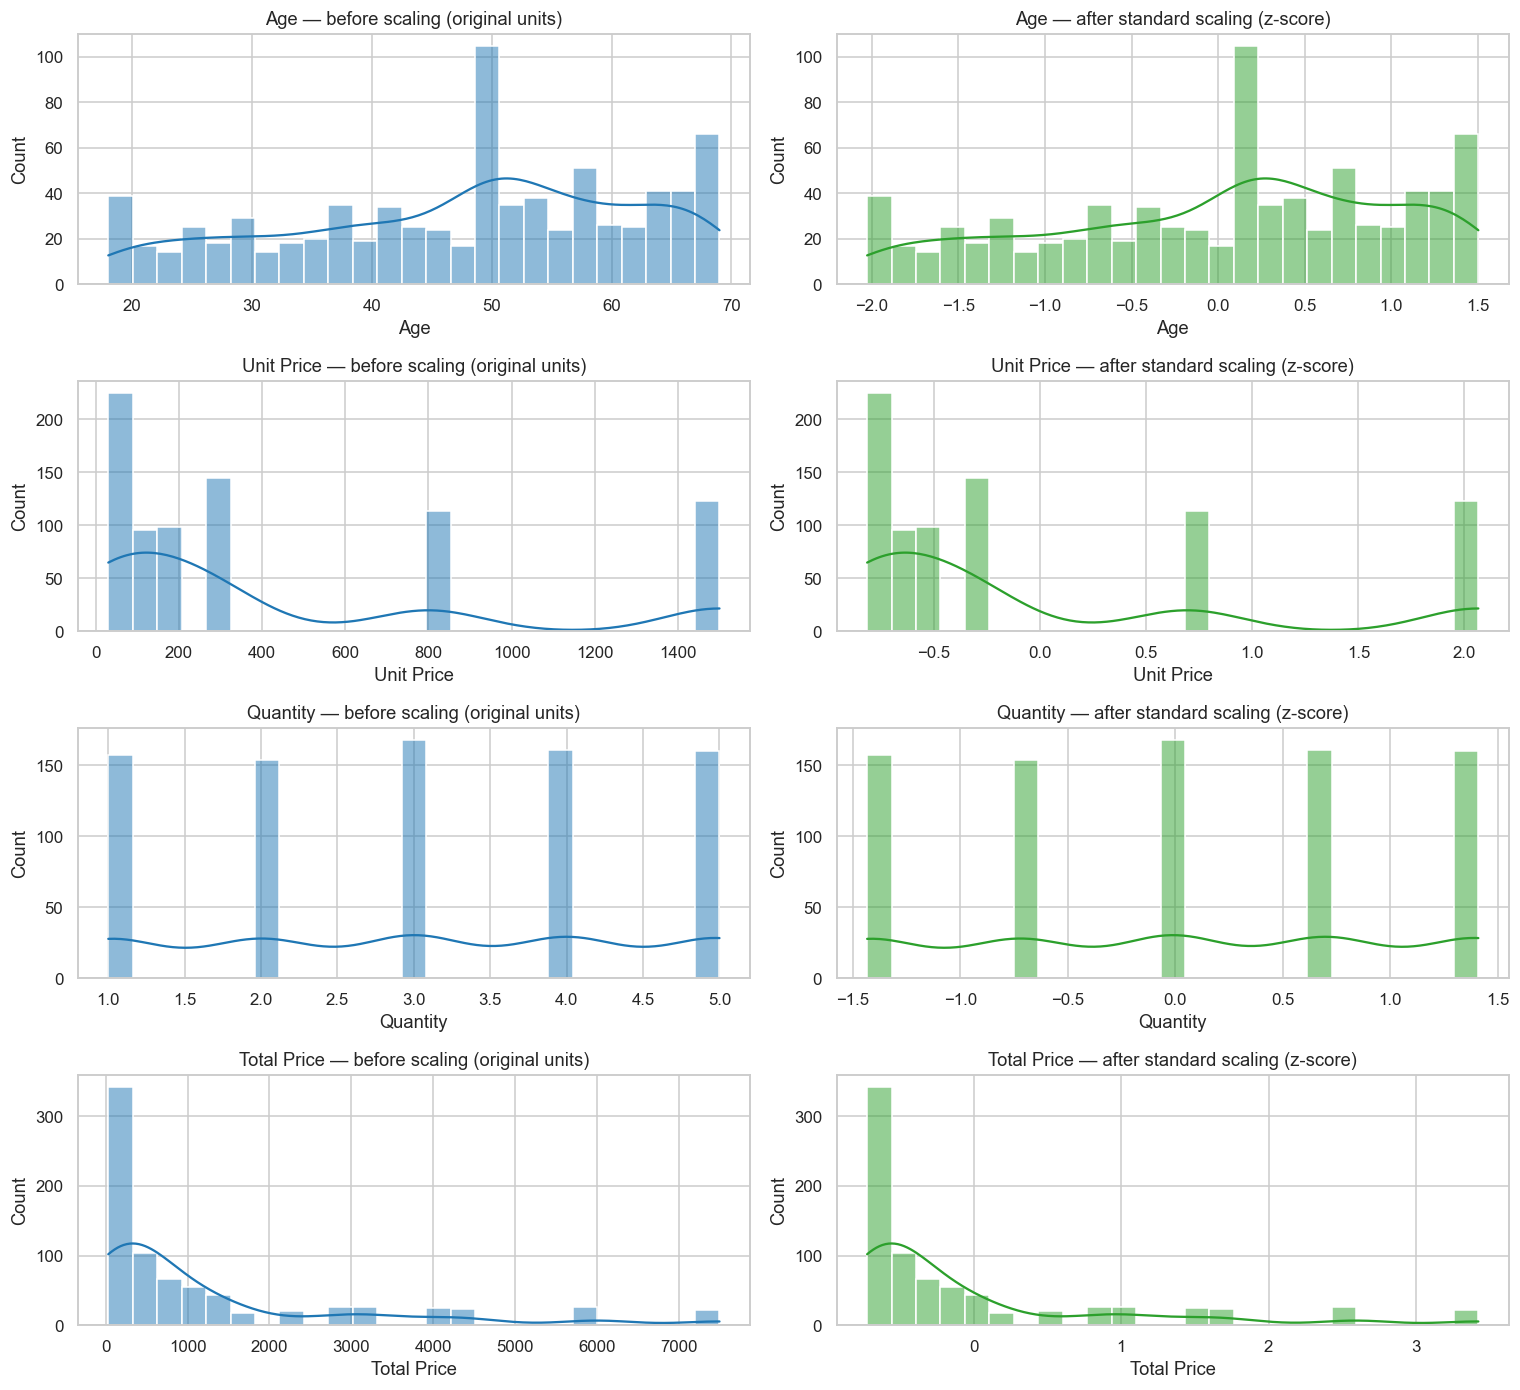

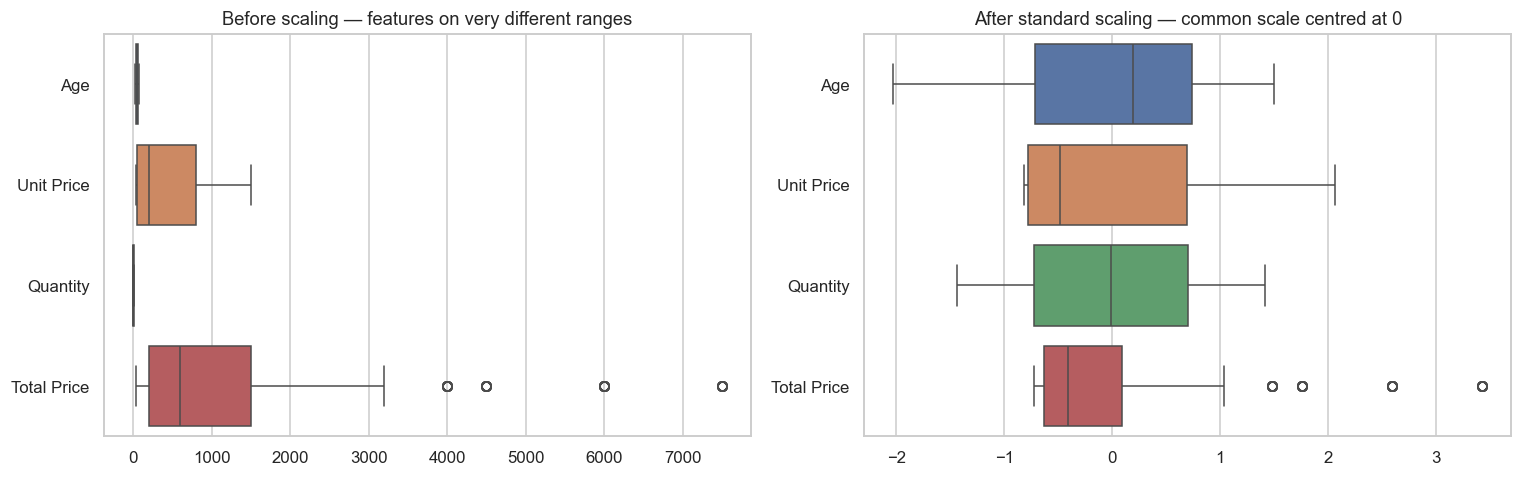

In [20]:
fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 3.2 * len(num_cols)))
for i, col in enumerate(num_cols):
    sns.histplot(X_train_enc[col], kde=True, bins=25, ax=axes[i, 0], color="tab:blue")
    axes[i, 0].set_title(f"{col} — before scaling (original units)")
    sns.histplot(X_train_scaled[col], kde=True, bins=25, ax=axes[i, 1], color="tab:green")
    axes[i, 1].set_title(f"{col} — after standard scaling (z-score)")
plt.tight_layout()
show_save("09_scaling_distributions_before_after")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=X_train_enc[num_cols], orient="h", ax=axes[0])
axes[0].set_title("Before scaling — features on very different ranges")
sns.boxplot(data=X_train_scaled[num_cols], orient="h", ax=axes[1])
axes[1].set_title("After standard scaling — common scale centred at 0")
plt.tight_layout()
show_save("10_scaling_boxplots_before_after")

**Comments on the comparison plots — effect of scaling**

* **Shape is unchanged:** in every pair of histograms the left and right panels look identical — same peaks (e.g. the seven price levels of `Unit Price`, the five values of `Quantity`), same skewness of `Total Price`, same flat shape of `Age`. Standard scaling is a linear transformation (subtract the mean, divide by the standard deviation), so it does not change the distribution or the correlations — only the x-axis.
* **Location and spread are harmonised:** before scaling the x-axes range from 1–5 (`Quantity`) to 0–7,500 (`Total Price`). After scaling all four features are centred at 0 with a standard deviation of 1, and most values lie between about −2 and +3. The right-hand box plot shows this: features that were invisible next to the price columns now have comparable boxes.
* **Why this confirms the choice:** because the outliers were corrected first, no feature is squashed by a few extreme points (which is what min-max scaling would have done to `Total Price`), and the long right tail of `Total Price` is kept as genuine information. The test set, transformed with the training mean and standard deviation, has a mean close to 0 and a standard deviation close to 1 — as expected for data from the same distribution — which confirms that the split and the scaling were done without leakage.

## 7. Other preprocessing

We checked each of the optional methods against the results of the EDA:

| Method | Applied? | Reason |
|---|---|---|
| Over-/under-sampling | **No** | This is a **regression** problem; there are no classes that could be imbalanced. The target `Shipping Fee` is spread evenly between 5 and 20 (skewness ≈ 0), so no range of the target is under-represented either. |
| Dimension reduction (PCA) | **No** | The final feature set has only 20 columns for 800 training rows (40 rows per feature), and PCA would turn interpretable features (product, region) into abstract components without a clear benefit. |
| Discretization | **No** | Binning `Age` or `Unit Price` would throw away information. `Unit Price` is already effectively discrete (7 list prices) and the EDA found no threshold effect that would justify bins. |
| **Feature engineering** | **Yes** | `Order Date` cannot be used directly by a model; we extract month and day-of-week as **cyclical** features. |
| **Feature selection** | **Yes** | `Total Price` and the `Category` dummies are perfectly redundant with other features after preprocessing. |

### 7.1 Feature engineering — cyclical date features

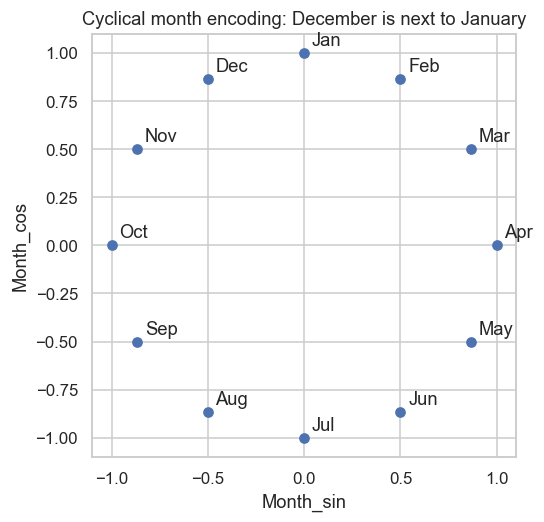

,Month_sin,Month_cos,Weekday_sin,Weekday_cos,Is_Weekend
776,0.500000,8.660254e-01,0.000000,1.000000,0
809,0.866025,-5.000000e-01,-0.433884,-0.900969,0
876,0.866025,-5.000000e-01,0.433884,-0.900969,0
669,0.500000,8.660254e-01,-0.974928,-0.222521,1
363,-1.000000,-1.836970e-16,0.781831,0.623490,0


In [21]:
def add_date_features(data):
    d = data["Order Date"]
    data["Month_sin"] = np.sin(2 * np.pi * (d.dt.month - 1) / 12)
    data["Month_cos"] = np.cos(2 * np.pi * (d.dt.month - 1) / 12)
    data["Weekday_sin"] = np.sin(2 * np.pi * d.dt.dayofweek / 7)
    data["Weekday_cos"] = np.cos(2 * np.pi * d.dt.dayofweek / 7)
    data["Is_Weekend"] = (d.dt.dayofweek >= 5).astype(int)
    return data.drop(columns="Order Date")

X_train_fe = add_date_features(X_train_scaled.copy())
X_test_fe = add_date_features(X_test_scaled.copy())

fig, ax = plt.subplots(figsize=(5, 5))
months = np.arange(1, 13)
ax.scatter(np.sin(2*np.pi*(months-1)/12), np.cos(2*np.pi*(months-1)/12))
for m in months:
    ax.annotate(pd.Timestamp(2023, m, 1).strftime("%b"),
                (np.sin(2*np.pi*(m-1)/12), np.cos(2*np.pi*(m-1)/12)), xytext=(5, 5), textcoords="offset points")
ax.set(title="Cyclical month encoding: December is next to January", xlabel="Month_sin", ylabel="Month_cos")
ax.set_aspect("equal")
show_save("11_cyclical_month")
X_train_fe[["Month_sin", "Month_cos", "Weekday_sin", "Weekday_cos", "Is_Weekend"]].head()

**Why:** the EDA (Brainstorming 7) suggested that shipping fees might vary over time (seasonal demand, promotions). A raw date or month number 1–12 would wrongly tell the model that December (12) is far away from January (1). Encoding month and weekday as sine/cosine pairs places them on a circle, so neighbouring periods are close to each other. The features are already in [−1, 1] and are therefore not scaled further. The calendar year is not used because the data cover only 2023 (plus three days in January 2024), so it carries no information. These features are created row by row from each order's own date, so there is no leakage.

### 7.2 Feature selection — removing redundant features

Total Price == Unit Price × Quantity for every training row: True

Product Name -> Category mapping (training set):


Category,Accessories,Electronics,Wearables
Product Name,,,
Headphones,96,0,0
Keyboard,116,0,0
Laptop,0,123,0
Monitor,0,145,0
Mouse,109,0,0
Smartphone,0,113,0
Smartwatch,0,0,98


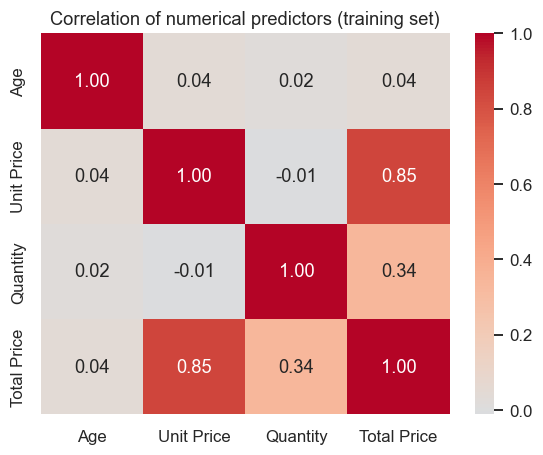

Removed: ['Total Price', 'Category_Accessories', 'Category_Electronics', 'Category_Wearables']
Final feature set: 20 features -> ['Gender', 'Age', 'Unit Price', 'Quantity', 'Region_East', 'Region_North', 'Region_South', 'Region_West', 'Product Name_Headphones', 'Product Name_Keyboard', 'Product Name_Laptop', 'Product Name_Monitor', 'Product Name_Mouse', 'Product Name_Smartphone', 'Product Name_Smartwatch', 'Month_sin', 'Month_cos', 'Weekday_sin', 'Weekday_cos', 'Is_Weekend']


In [22]:
# 1) Total Price is an exact function of Unit Price and Quantity (after outlier handling)
exact = np.isclose(X_train["Total Price"], X_train["Unit Price"] * X_train["Quantity"]).all()
print("Total Price == Unit Price × Quantity for every training row:", exact)

# 2) Category is fully determined by Product Name
print("\nProduct Name -> Category mapping (training set):")
display(pd.crosstab(X_train["Product Name"], X_train["Category"]))

# 3) Correlations among the numerical predictors (training set)
plt.figure(figsize=(6, 4.5))
sns.heatmap(X_train_fe[["Age", "Unit Price", "Quantity", "Total Price"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numerical predictors (training set)")
show_save("12_feature_selection_correlation")

drop_cols = ["Total Price"] + [c for c in X_train_fe.columns if c.startswith("Category_")]
X_train_final = X_train_fe.drop(columns=drop_cols)
X_test_final = X_test_fe.drop(columns=drop_cols)
print("Removed:", drop_cols)
print("Final feature set:", X_train_final.shape[1], "features ->", list(X_train_final.columns))

**Why these features were removed**

* **`Total Price`:** after the outlier correction, `Total Price = Unit Price × Quantity` holds exactly for every order, and it is strongly correlated with `Unit Price` (see heatmap). It therefore adds **no new information** but creates multicollinearity, which makes regression coefficients unstable and hard to interpret. A non-linear model can still learn the interaction from `Unit Price` and `Quantity`. (The Part 1 question "does `Total Price` embed the shipping fee?" is also answered: it does not, so it is removed for redundancy, not for leakage.)
* **`Category` dummies:** the crosstab shows that every product belongs to exactly one category (e.g. Laptop → Electronics), so the category columns are a linear combination of the product columns (perfect multicollinearity, the "dummy variable trap"). `Product Name` is kept because it is the more detailed of the two.
* **Note for modelling:** `Region` and `Product Name` keep all their dummy columns (useful for tree-based and regularised models and easier to interpret). For an *unregularised* linear regression in the next part, one dummy per variable should be dropped as the reference level (`drop="first"`) to avoid the dummy-variable trap.
* **Earlier (Section 2):** `Customer ID` (identifier, no generalisable information) and `Shipping Status` (post-shipping information → leakage).

## 8. Final preprocessed datasets

In [23]:
train_out = pd.concat([X_train_final, y_train], axis=1)
test_out = pd.concat([X_test_final, y_test], axis=1)
train_out.to_csv(OUT_DIR / "ecommerce_train_preprocessed.csv", index=False)
test_out.to_csv(OUT_DIR / "ecommerce_test_preprocessed.csv", index=False)

print("Training set:", train_out.shape, "| Test set:", test_out.shape)
print("Missing values — train:", int(train_out.isna().sum().sum()), "| test:", int(test_out.isna().sum().sum()))
print("Saved to:", OUT_DIR)
train_out.head()

Training set: (800, 21) | Test set: (200, 21)
Missing values — train: 0 | test: 0
Saved to: processed_data


,Gender,Age,Unit Price,Quantity,Region_East,Region_North,Region_South,Region_West,Product Name_Headphones,Product Name_Keyboard,...,Product Name_Monitor,Product Name_Mouse,Product Name_Smartphone,Product Name_Smartwatch,Month_sin,Month_cos,Weekday_sin,Weekday_cos,Is_Weekend,Shipping Fee
776,0,1.363691,-0.814798,0.699388,0,1,0,0,0,0,...,0,1,0,0,0.500000,8.660254e-01,0.000000,1.000000,0,19.59
809,0,-0.642627,-0.775609,1.410329,0,0,1,0,0,1,...,0,0,0,0,0.866025,-5.000000e-01,-0.433884,-0.900969,0,12.25
876,1,0.671857,2.065540,1.410329,0,0,0,1,0,0,...,0,0,0,0,0.866025,-5.000000e-01,0.433884,-0.900969,0,7.57
669,0,-1.265278,-0.481697,0.699388,1,0,0,0,0,0,...,0,0,0,1,0.500000,8.660254e-01,-0.974928,-0.222521,1,17.93
363,0,-1.542011,-0.775609,0.699388,1,0,0,0,0,1,...,0,0,0,0,-1.000000,-1.836970e-16,0.781831,0.623490,0,7.33


### Summary of the preprocessing of Dataset 3

| Step | What was done | Main effect |
|---|---|---|
| Split | 80/20, stratified by product, done before any fitted step | 800 training / 200 test orders with identical product mix; no leakage |
| Missing values | MCAR diagnosed; median (`Age`) and most-frequent (`Region`) imputation | No rows lost; small, acceptable reduction in `Age` variance |
| Outliers | Per-product IQR detection; winsorization of `Unit Price` | 20 inflated prices corrected; data now internally consistent |
| Encoding | Label (`Gender`), one-hot (`Region`, `Product Name`, `Category`) in a loop | All predictors numerical without inventing false orders |
| Scaling | Standard scaling of numerical predictors | Comparable scales (mean 0, std 1); shapes preserved |
| Other | Cyclical date features; removal of `Total Price` and `Category` | Usable time information; no redundant / collinear features |

The resulting datasets are ready for the regression models of the next project part. A note for that stage: the EDA found only weak linear relationships between the predictors and `Shipping Fee`, so non-linear models and interaction effects (e.g. product × region) should be compared with linear baselines.

### References
* scikit-learn documentation — *Preprocessing data*, *Imputation of missing values*, `train_test_split`: https://scikit-learn.org/stable/
* missingno documentation: https://github.com/ResidentMario/missingno
* NIST/SEMATECH e-Handbook of Statistical Methods — *Detection of Outliers*: https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
* Little, R. J. A. & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley — definitions of MCAR/MAR/MNAR.